# 06 · Clustering P4: perfiles de puntualidad
TA Aprendizaje de Máquina, grupo 5. Entregable 2 (complementario).

**Objetivo.** Describir los patrones de puntualidad de las vueltas con su vector de 18 desviaciones y comprobar si los grupos respaldan los umbrales de P2. Solo se usan vueltas de entrenamiento con los 18 puntos registrados (regla de 60 min aplicada).

Algoritmos: K-medias, K-medianas (implementación propia con distancia L1), jerárquico de Ward, mezcla de gaussianas (EM) y DBSCAN sobre las componentes principales. Métricas: silueta, Davies-Bouldin, Calinski-Harabasz y estabilidad por remuestreo (ARI).

**Entradas:** `data/raw/Times.csv`. **Salidas:** `results/tables/06_*.csv`, `results/figures/06_*.png`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.datos import COL_DIF, aplicar_regla_extremos, cargar_times
from src.particion import INICIO_PRUEBA
from src import graficos

SEMILLA = 42
DIR_RAW = RAIZ / "data" / "raw"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
graficos.estilo()

## 1. Vectores de desviación

In [2]:
v = aplicar_regla_extremos(cargar_times(DIR_RAW / "Times.csv"))
v = v[(v["fecha"] < INICIO_PRUEBA) & v[COL_DIF].notna().all(axis=1)].reset_index(drop=True)
X = v[COL_DIF].to_numpy()
print(f"Vueltas completas de entrenamiento: {len(X)}")

Vueltas completas de entrenamiento: 2289


## 2. PCA

In [3]:
pca = PCA(random_state=SEMILLA).fit(X)
var = pd.Series(np.cumsum(pca.explained_variance_ratio_[:6]) * 100, index=[f"CP{i}" for i in range(1, 7)]).round(1)
Z = pca.transform(X)[:, :2]
var

CP1    84.6
CP2    91.2
CP3    94.9
CP4    96.3
CP5    97.1
CP6    97.7
dtype: float64

## 3. Elección del número de grupos

In [4]:
def k_medianas(X, k, semilla=SEMILLA, iteraciones=100):
    """K-medianas: asignación por distancia L1 y centros como mediana por coordenada."""
    rng = np.random.default_rng(semilla)
    centros = X[rng.choice(len(X), k, replace=False)]
    for _ in range(iteraciones):
        etiquetas = np.abs(X[:, None, :] - centros[None]).sum(axis=2).argmin(axis=1)
        nuevos = np.array([np.median(X[etiquetas == j], axis=0) if np.any(etiquetas == j) else centros[j]
                           for j in range(k)])
        if np.allclose(nuevos, centros):
            break
        centros = nuevos
    return etiquetas


def metricas(X, etiquetas):
    if len(set(etiquetas)) < 2:
        return {"silueta": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {"silueta": silhouette_score(X, etiquetas, random_state=SEMILLA),
            "davies_bouldin": davies_bouldin_score(X, etiquetas),
            "calinski_harabasz": calinski_harabasz_score(X, etiquetas)}


filas = []
for k in range(2, 7):
    gmm = GaussianMixture(k, covariance_type="full", n_init=3, random_state=SEMILLA).fit(X)
    algoritmos = {
        "K-medias": KMeans(k, n_init=20, random_state=SEMILLA).fit_predict(X),
        "K-medianas": k_medianas(X, k),
        "Jerárquico (Ward)": AgglomerativeClustering(k, linkage="ward").fit_predict(X),
        "GMM (EM)": gmm.predict(X),
    }
    for nombre, et in algoritmos.items():
        filas.append({"algoritmo": nombre, "k": k, **metricas(X, et), "BIC": gmm.bic(X) if nombre == "GMM (EM)" else np.nan})
eleccion = pd.DataFrame(filas)
eleccion.round(3).to_csv(DIR_TAB / "06_eleccion_k.csv", index=False)
eleccion.pivot(index="k", columns="algoritmo", values="silueta").round(3)

algoritmo,GMM (EM),Jerárquico (Ward),K-medianas,K-medias
k,,,,
2,0.362,0.706,0.427,0.703
3,0.394,0.586,0.479,0.571
4,0.132,0.354,0.306,0.354
5,0.114,0.359,0.256,0.334
6,0.093,0.241,0.215,0.237


In [5]:
eleccion.pivot(index="k", columns="algoritmo", values="davies_bouldin").round(3)

algoritmo,GMM (EM),Jerárquico (Ward),K-medianas,K-medias
k,,,,
2,6.350,0.402,0.934,0.419
3,1.095,0.674,0.792,0.681
4,1.462,0.960,0.995,0.935
5,1.560,0.916,1.106,0.934
6,1.976,1.059,1.298,1.096


## 4. DBSCAN sobre las dos primeras componentes
`eps` se toma del codo de la distancia al 10.º vecino (percentil 95).

In [6]:
dist = np.sort(NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)[0][:, -1])
eps = float(np.percentile(dist, 95))
et_db = DBSCAN(eps=eps, min_samples=10).fit_predict(Z)
dbscan = {"eps": round(eps, 3), "grupos": int(len(set(et_db)) - (-1 in et_db)), "pct_ruido": round(100 * np.mean(et_db == -1), 2),
          **{m: round(val, 3) for m, val in metricas(Z[et_db >= 0], et_db[et_db >= 0]).items()}}
pd.Series(dbscan).to_csv(DIR_TAB / "06_dbscan.csv")
pd.Series(dbscan)

eps                     4.333
grupos                  2.000
pct_ruido               2.580
silueta                 0.774
davies_bouldin          0.319
calinski_harabasz    3626.188
dtype: float64

## 5. Estabilidad de K-medias (ARI por remuestreo)
Se evalúan k = 2 (mejor silueta) y k = 3 (segunda mejor y la que se usa para describir perfiles).

In [7]:
rng = np.random.default_rng(SEMILLA)
modelos_km, estab = {}, []
for k in (2, 3):
    modelos_km[k] = KMeans(k, n_init=20, random_state=SEMILLA).fit(X)
    ari = [adjusted_rand_score(modelos_km[k].labels_,
                               KMeans(k, n_init=10, random_state=s).fit(X[rng.choice(len(X), len(X))]).predict(X))
           for s in range(30)]
    estab.append({"k": k, "ARI_media": np.mean(ari), "ARI_min": np.min(ari)})
estabilidad = pd.DataFrame(estab).round(3)
estabilidad.to_csv(DIR_TAB / "06_estabilidad.csv", index=False)
estabilidad

,k,ARI_media,ARI_min
0,2,0.998,0.996
1,3,0.982,0.935


## 6. Perfiles de los grupos (k = 3)
Con k = 2 solo se separa el grupo de vueltas muy adelantadas de la madrugada; k = 3 agrega un grupo de vueltas atrasadas, lo que permite contrastar las tres clases de P2.

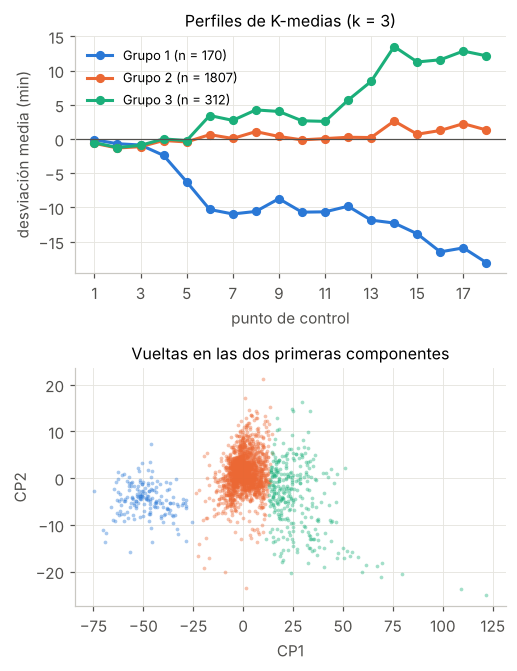

,vueltas,atraso_final_medio,hora_inicio_media,pct_sabado
grupo,,,,
Grupo 1,170,-18.06,5.08,14.71
Grupo 2,1807,1.31,10.39,4.93
Grupo 3,312,12.14,11.97,73.72


In [8]:
K_PERFILES = 3
completo = modelos_km[K_PERFILES]
v["grupo"] = completo.labels_
orden = v.groupby("grupo")["dif_18"].mean().sort_values().index
nombres = {g: f"Grupo {i + 1}" for i, g in enumerate(orden)}
v["grupo"] = v["grupo"].map(nombres)
perfil = v.groupby("grupo")[COL_DIF].mean()
resumen = v.groupby("grupo").agg(vueltas=("id", "size"), atraso_final_medio=("dif_18", "mean"),
                                 hora_inicio_media=("prog_1", lambda s: s.mean() / 60),
                                 pct_sabado=("fecha", lambda s: 100 * np.mean(s.dt.dayofweek == 5))).round(2)
resumen.to_csv(DIR_TAB / "06_perfiles.csv")

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 6.2))
for i, (g, fila) in enumerate(perfil.iterrows()):
    ejes[0].plot(range(1, 19), fila.to_numpy(), marker="o", color=graficos.PALETA[i], label=f"{g} (n = {resumen.loc[g, 'vueltas']})")
    m = (v["grupo"] == g).to_numpy()
    ejes[1].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.4, color=graficos.PALETA[i], linewidths=0, label=g)
ejes[0].axhline(0, color=graficos.TEXTO_SEC, linewidth=0.8)
ejes[0].set(xlabel="punto de control", ylabel="desviación media (min)", xticks=range(1, 19, 2),
            title=f"Perfiles de K-medias (k = {K_PERFILES})")
ejes[0].legend(loc="upper left")
ejes[1].set(xlabel="CP1", ylabel="CP2", title="Vueltas en las dos primeras componentes")
graficos.guardar(fig, DIR_FIG / "06_perfiles_kmedias.png")
resumen

## 7. Conclusiones
- Se usan 2.289 vueltas completas de entrenamiento. La primera componente principal explica el 84,6 % de la varianza: casi toda la variación es un desplazamiento común de la curva de atraso.
- La silueta es máxima con k = 2 (0,70), pero solo separa las vueltas de madrugada muy adelantadas. Con k = 3 (silueta 0,57, ARI 0,98) aparecen tres perfiles: adelantado (170 vueltas, −18,1 min, inicio medio 5 h), a tiempo (1.807, +1,3 min) y atrasado (312, +12,1 min, 74 % en sábado).
- Los tres perfiles coinciden con las clases de P2 y con los efectos de franja y día de P1. K-medianas y GMM dan peor silueta; DBSCAN en el plano PCA encuentra 2 grupos con 2,6 % de ruido.

In [9]:
import platform, sklearn
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
